# Task 2: Background removal for a meeting camera

**Goal.** Train a **binary segmentation** model (a **U-Net**) that predicts, for every pixel, *person or background*.
Then use it on your laptop camera to put a new background behind you, like a video call.

**Data.** [Supervisely filtered person dataset](https://www.kaggle.com/datasets/tapakah68/supervisely-filtered-segmentation-person-dataset): 2,667 photos with a person mask each.
Check the dataset's licence on Kaggle before using it beyond this class.

# Streamlit link
# https://background-changer.streamlit.app/

## 0. Setup

In [4]:
!pip -q install kagglehub opencv-contrib-python-headless

In [5]:
!pip -q install segmentation-models-pytorch

In [6]:
import os, glob, random, time
import numpy as np, cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights
from PIL import Image

SEED = 42

## 1. Download and look at the data
The first cell downloads the dataset. It is a few hundred MB, so it takes a minute.

In [7]:
# [colab-only] download the dataset from Kaggle
import kagglehub

DATASET = "tapakah68/supervisely-filtered-segmentation-person-dataset"
try:
    DATA_ROOT = kagglehub.dataset_download(DATASET)
except Exception as e:
    # Fallback: use your own Kaggle API key (Kaggle > Settings > API > Create New Token)
    print("kagglehub could not download without login:", type(e).__name__)
    from google.colab import files
    print("Upload your kaggle.json")
    files.upload()
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    !cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
    !kaggle datasets download -d {DATASET} -p /content/data --unzip -q
    DATA_ROOT = "/content/data"
print("dataset folder:", DATA_ROOT)

dataset folder: /kaggle/input/datasets/tapakah68/supervisely-filtered-segmentation-person-dataset


In [8]:
# Find every image and its mask, and pair them by file name.
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp")
IMG_DIR = None    # set both by hand only if the automatic search below fails
MASK_DIR = None

def stem(path):
    s = os.path.splitext(os.path.basename(path))[0].lower()
    for tag in ("_mask", "-mask", "mask_", "mask-", "_seg", "_label"):
        s = s.replace(tag, "")
    return s

def find_pairs(root):
    files = [f for f in glob.glob(os.path.join(root, "**", "*"), recursive=True)
             if f.lower().endswith(IMG_EXT)]
    rel = lambda f: os.path.relpath(f, root).lower()
    is_mask    = lambda f: "mask" in rel(f)
    is_collage = lambda f: "collage" in rel(f)     # photo + mask drawn together: NOT the original photo
    imgs  = {stem(f): f for f in files if not is_mask(f) and not is_collage(f)}
    masks = {stem(f): f for f in files if is_mask(f)}
    keys = sorted(set(imgs) & set(masks))
    return [(imgs[k], masks[k]) for k in keys]

if IMG_DIR and MASK_DIR:
    imgs  = {stem(f): f for f in glob.glob(os.path.join(IMG_DIR, "*"))}
    masks = {stem(f): f for f in glob.glob(os.path.join(MASK_DIR, "*"))}
    pairs = [(imgs[k], masks[k]) for k in sorted(set(imgs) & set(masks))]
else:
    pairs = find_pairs(DATA_ROOT)

print("image/mask pairs found:", len(pairs))
from collections import Counter
print("folders used:", dict(Counter(os.path.basename(os.path.dirname(p)) for pr in pairs for p in pr)))
if not pairs:
    for dp, dn, fn in os.walk(DATA_ROOT):
        print(dp, "->", len(fn), "files", fn[:3])
    raise RuntimeError("No pairs found. Look at the folder listing above and set IMG_DIR and MASK_DIR.")
print(pairs[0])

image/mask pairs found: 2663
folders used: {'images': 2663, 'masks': 2663}
('/kaggle/input/datasets/tapakah68/supervisely-filtered-segmentation-person-dataset/supervisely_person_clean_2667_img/supervisely_person_clean_2667_img/images/ds10_pexels-photo-687782.png', '/kaggle/input/datasets/tapakah68/supervisely-filtered-segmentation-person-dataset/supervisely_person_clean_2667_img/supervisely_person_clean_2667_img/masks/ds10_pexels-photo-687782.png')


In [9]:
def read_mask(path):
    """Mask file -> 2-D array. If the file has colour channels, take the strongest one."""
    return cv2.imread(path, cv2.IMREAD_COLOR).max(axis=2)

# How are the masks encoded? The person may be 255, 1 or something else. Never guess: measure.
sample = random.sample(pairs, min(100, len(pairs)))
vals = np.unique(np.concatenate([np.unique(read_mask(mp)) for _, mp in sample]))
MASK_MAX = int(vals.max())
MASK_THRESHOLD = MASK_MAX / 2        # above this = person, whatever the file uses (255, 1, ...)
frac = np.mean([(read_mask(mp) > MASK_THRESHOLD).mean() for _, mp in sample])
print("distinct mask values:", vals[:10], "| max:", MASK_MAX, "| threshold:", MASK_THRESHOLD)
print(f"average person share of an image: {frac:.1%}")
assert MASK_MAX > 0 and 0.02 < frac < 0.9, "The masks look empty or full. Check the pairing and the values printed above."

# An image and its mask must have the same size. Many mismatches mean the wrong folder was paired.
mismatch = sum(cv2.imread(ip).shape[:2] != read_mask(mp).shape[:2] for ip, mp in sample)
print("image/mask size mismatches in the sample:", mismatch, "of", len(sample))
assert mismatch < 0.5 * len(sample), "Most images have a different size than their mask: the wrong image folder is probably paired. Check 'folders used' above."

distinct mask values: [  0 255] | max: 255 | threshold: 127.5
average person share of an image: 31.9%
image/mask size mismatches in the sample: 0 of 100


**Always open a mask and print its values before training.** Masks are stored as PNG, but the foreground may be `255`, `1`, or anything else.
The cell above measured the mask values and set `MASK_THRESHOLD` for you. Look at the `mask values` printed above each mask too.

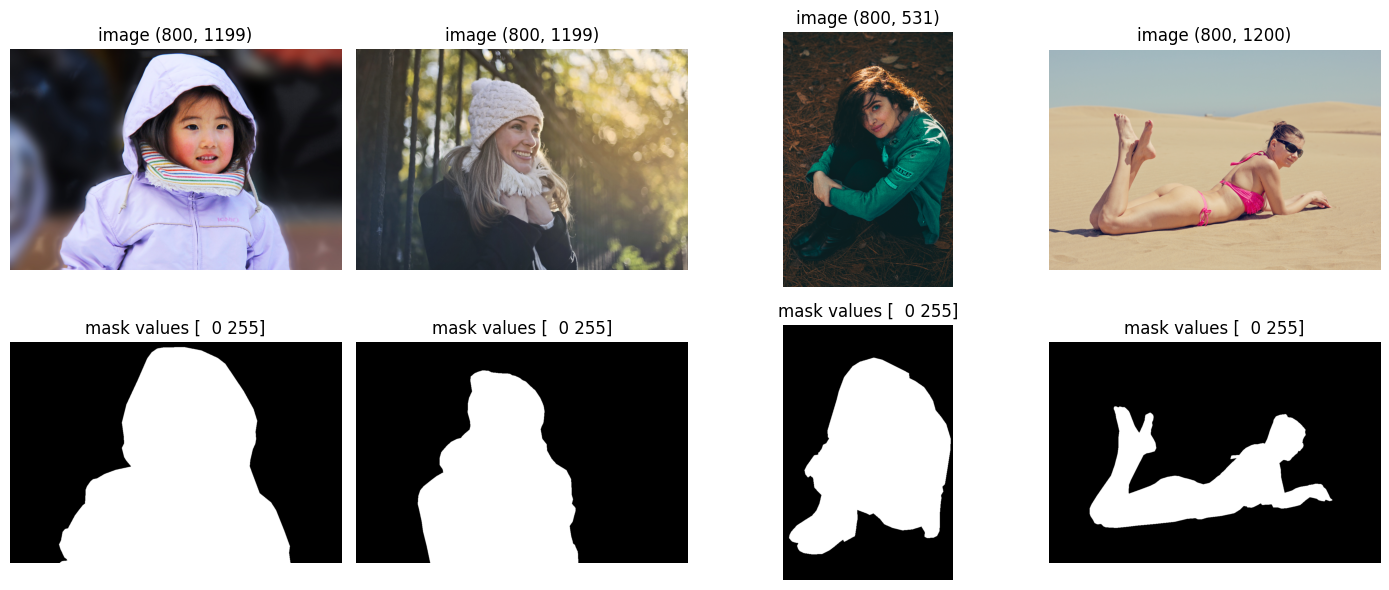

In [10]:
# Look at the data. A mask is data: print its values before you trust it.
fig, ax = plt.subplots(2, 4, figsize=(14, 6))
for k, i in enumerate(random.sample(range(len(pairs)), 4)):
    ip, mp = pairs[i]
    img = cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB)
    msk = read_mask(mp)
    ax[0, k].imshow(img); ax[0, k].set_title(f"image {img.shape[:2]}"); ax[0, k].axis("off")
    ax[1, k].imshow(msk, cmap="gray"); ax[1, k].set_title(f"mask values {np.unique(msk)[:4]}"); ax[1, k].axis("off")
plt.tight_layout(); plt.show()

In [11]:
# Train / validation split (the validation images are never used for training)
random.Random(SEED).shuffle(pairs)
n_val = int(0.15 * len(pairs))
val_pairs, train_pairs = pairs[:n_val], pairs[n_val:]
print("train:", len(train_pairs), " val:", len(val_pairs))

train: 2264  val: 399


In [12]:
# 1. Define the Dataset
class PersonDataset(Dataset):
    def __init__(self, pairs, img_size=(256, 256)):
        self.pairs = pairs
        self.img_size = img_size
        self.transform = transforms.Compose([
            transforms.Resize(img_size),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])
        self.mask_transform = transforms.Compose([
            transforms.Resize(img_size, interpolation=Image.NEAREST),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]
        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        image_tensor = self.transform(image)
        mask_tensor = self.mask_transform(mask)
        mask_tensor = (mask_tensor > (MASK_THRESHOLD / 255.0)).float()
        return image_tensor, mask_tensor

In [13]:
# 2. Setup Data Loaders
train_dataset = PersonDataset(train_pairs, img_size=(384, 384))
val_dataset   = PersonDataset(val_pairs,   img_size=(384, 384))

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=2, pin_memory=True)



In [14]:
# 3. Load Pre-trained U-Net Model and Setup Loss & Optimizer
import segmentation_models_pytorch as smp

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

# Load a U-Net with a pre-trained resnet34 backbone
model = smp.Unet(
    encoder_name="resnet34",        # Use resnet34 backbone pre-trained on ImageNet
    encoder_weights="imagenet",     # Load pre-trained weights
    in_channels=3,                  # Input channels (RGB)
    classes=1                       # Binary segmentation (person vs background)
).to(device)

# Define Loss & Optimizer
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

Using device: cuda


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

In [15]:
import torch
import torch.nn as nn

class DiceLoss(nn.Module):
    def __init__(self, eps=1e-7):
        super(DiceLoss, self).__init__()
        self.eps = eps

    def forward(self, logits, targets):
        num = targets.size(0)
        probs = torch.sigmoid(logits)
        m1 = probs.view(num, -1)
        m2 = targets.view(num, -1)
        intersection = (m1 * m2).sum(1)
        score = 2. * (intersection + self.eps) / (m1.sum(1) + m2.sum(1) + self.eps)
        return 1. - score.mean()

class BCEDiceLoss(nn.Module):
    def __init__(self):
        super(BCEDiceLoss, self).__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()

    def forward(self, logits, targets):
        return self.bce(logits, targets) + self.dice(logits, targets)

def calculate_iou(logits, targets, threshold=0.5, eps=1e-7):
    with torch.no_grad():
        probs = torch.sigmoid(logits)
        preds = (probs > threshold).float()
        intersection = (preds * targets).sum(dim=(1, 2, 3))
        union = (preds + targets).sum(dim=(1, 2, 3)) - intersection
        iou = (intersection + eps) / (union + eps)
        return iou.mean().item()

# Override criterion with the new hybrid loss
criterion = BCEDiceLoss()
print("Criterion updated to BCE-Dice Loss!")

Criterion updated to BCE-Dice Loss!


In [16]:
print(type(model))
x = next(iter(train_loader))[0][:2].to(device)
print(type(model(x)))

<class 'segmentation_models_pytorch.decoders.unet.model.Unet'>
<class 'torch.Tensor'>


In [17]:
import os
import torch
import torch.nn as nn

class DiceLoss(nn.Module):
    def __init__(self, eps=1e-7):
        super().__init__()
        self.eps = eps

    def forward(self, logits, targets):
        num = targets.size(0)
        probs = torch.sigmoid(logits)
        m1 = probs.view(num, -1)
        m2 = targets.view(num, -1)
        intersection = (m1 * m2).sum(1)
        score = 2. * (intersection + self.eps) / (m1.sum(1) + m2.sum(1) + self.eps)
        return 1. - score.mean()

class BCEDiceLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()

    def forward(self, logits, targets):
        return self.bce(logits, targets) + self.dice(logits, targets)


# ---- Metrics (per image, on hard 0/1 predictions) ----
def batch_iou(logits, targets, threshold=0.5, eps=1e-7):
    """IoU for every image in the batch -> tensor of shape [B]."""
    preds = (torch.sigmoid(logits) > threshold).float()
    inter = (preds * targets).sum(dim=(1, 2, 3))
    union = (preds + targets).sum(dim=(1, 2, 3)) - inter
    return (inter + eps) / (union + eps)

def batch_dice(logits, targets, threshold=0.5, eps=1e-7):
    """Dice (F1) for every image in the batch -> tensor of shape [B]."""
    preds = (torch.sigmoid(logits) > threshold).float()
    inter = (preds * targets).sum(dim=(1, 2, 3))
    total = preds.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))
    return (2 * inter + eps) / (total + eps)

def calculate_iou(logits, targets, threshold=0.5, eps=1e-7):
    """Mean IoU of a batch (kept so older cells still work)."""
    with torch.no_grad():
        return batch_iou(logits, targets, threshold, eps).mean().item()


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    """Average loss, IoU and Dice over a whole loader (weighted per image)."""
    model.eval()
    n, loss_sum, iou_sum, dice_sum = 0, 0.0, 0.0, 0.0
    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        logits = model(imgs)
        b = imgs.size(0)
        loss_sum += criterion(logits, masks).item() * b
        iou_sum += batch_iou(logits, masks).sum().item()
        dice_sum += batch_dice(logits, masks).sum().item()
        n += b
    return loss_sum / n, iou_sum / n, dice_sum / n


criterion = BCEDiceLoss()
print("Criterion: BCE + Dice loss")

# 5. Fine-tuning loop with early stopping, best-weight saving and IoU/Dice tracking
EPOCH = 15
patience = 3
best_val_loss = float('inf')
patience_counter = 0
best_model_path = "unet_background_segmentation.pt"
history = []

print("Starting U-Net fine-tuning with validation monitoring...")
for epoch in range(EPOCH):
    # ---- Training ----
    model.train()
    running_loss, running_iou, seen = 0.0, 0.0, 0
    for batch_idx, (imgs, masks) in enumerate(train_loader):
        imgs, masks = imgs.to(device), masks.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)            # U-Net returns the logits tensor directly
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        b = imgs.size(0)
        running_loss += loss.item() * b
        with torch.no_grad():
            running_iou += batch_iou(outputs, masks).sum().item()
        seen += b

        if (batch_idx + 1) % 40 == 0:
            print(f"Epoch [{epoch+1}/{EPOCH}], Batch [{batch_idx+1}/{len(train_loader)}], "
                  f"Train Loss: {running_loss / seen:.4f}, Train IoU: {running_iou / seen:.4f}")

    train_loss, train_iou = running_loss / seen, running_iou / seen

    # ---- Validation ----
    val_loss, val_iou, val_dice = evaluate(model, val_loader, criterion, device)
    history.append(dict(epoch=epoch + 1, train_loss=train_loss, train_iou=train_iou,
                        val_loss=val_loss, val_iou=val_iou, val_dice=val_dice))
    print(f"Epoch [{epoch+1}/{EPOCH}] | Train Loss: {train_loss:.4f}, IoU: {train_iou:.4f} "
          f"| Val Loss: {val_loss:.4f}, IoU: {val_iou:.4f}, Dice: {val_dice:.4f}")

    # ---- Early stopping and saving the best weights ----
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        try:
            scripted_model = torch.jit.script(model)
            scripted_model.save(best_model_path)
            print(f"New best validation loss! Saved TorchScript model to '{best_model_path}'.")
        except Exception as e:
            torch.save(model.state_dict(), "unet_weights.pth")
            print(f"New best validation loss! Saved state_dict (scripting failed: {e})")
    else:
        patience_counter += 1
        print(f"Validation loss did not improve. Early stopping counter: {patience_counter}/{patience}")
        if patience_counter >= patience:
            print("Early stopping triggered! Training stopped.")
            break

print("U-Net fine-tuning process finished!")

# ---- Final numbers for the SAVED best model ----
if os.path.exists(best_model_path):
    best_model = torch.jit.load(best_model_path, map_location=device)
    f_loss, f_iou, f_dice = evaluate(best_model, val_loader, criterion, device)
    print(f"\nBest saved model on {len(val_loader.dataset)} validation images:")
    print(f"  IoU : {f_iou:.4f}")
    print(f"  Dice: {f_dice:.4f}")
    print(f"  Loss: {f_loss:.4f}")

Criterion: BCE + Dice loss
Starting U-Net fine-tuning with validation monitoring...
Epoch [1/15], Batch [40/142], Train Loss: 0.8589, Train IoU: 0.6167
Epoch [1/15], Batch [80/142], Train Loss: 0.7185, Train IoU: 0.6961
Epoch [1/15], Batch [120/142], Train Loss: 0.6475, Train IoU: 0.7362
Epoch [1/15] | Train Loss: 0.6157, IoU: 0.7536 | Val Loss: 0.3754, IoU: 0.8813, Dice: 0.9331
New best validation loss! Saved TorchScript model to 'unet_background_segmentation.pt'.
Epoch [2/15], Batch [40/142], Train Loss: 0.3497, Train IoU: 0.8934
Epoch [2/15], Batch [80/142], Train Loss: 0.3327, Train IoU: 0.8963
Epoch [2/15], Batch [120/142], Train Loss: 0.3142, Train IoU: 0.8996
Epoch [2/15] | Train Loss: 0.3071, IoU: 0.8994 | Val Loss: 0.2524, IoU: 0.9037, Dice: 0.9462
New best validation loss! Saved TorchScript model to 'unet_background_segmentation.pt'.
Epoch [3/15], Batch [40/142], Train Loss: 0.2604, Train IoU: 0.9071
Epoch [3/15], Batch [80/142], Train Loss: 0.2357, Train IoU: 0.9148
Epoch [3

## Meeting-camera test
Take a photo with your laptop camera, choose a new background, and let your model remove the old one.
The edge is blended with **alpha** (Session 2): a hard 0/1 mask looks jagged, a slightly blurred one looks natural.

Allow camera access when the browser asks. Run the cells below in order.

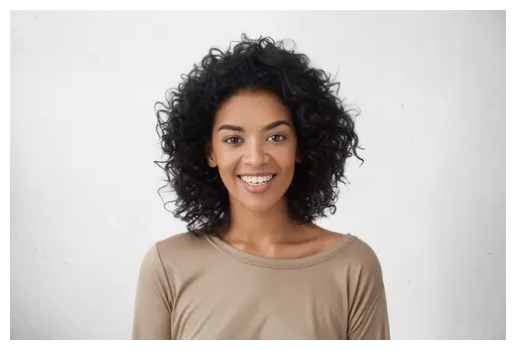

In [18]:
# [colab-only] take a photo with your laptop camera (the browser will ask for permission)
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename="photo.jpg", quality=0.9):
    js = Javascript('''
      async function takePhoto(quality) {
        const div = document.createElement('div');
        const btn = document.createElement('button');
        btn.textContent = 'Capture'; div.appendChild(btn);
        const video = document.createElement('video');
        video.style.display = 'block';
        const stream = await navigator.mediaDevices.getUserMedia({video: true});
        document.body.appendChild(div); div.appendChild(video);
        video.srcObject = stream; await video.play();
        google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
        await new Promise((resolve) => btn.onclick = resolve);
        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth; canvas.height = video.videoHeight;
        canvas.getContext('2d').drawImage(video, 0, 0);
        stream.getVideoTracks()[0].stop(); div.remove();
        return canvas.toDataURL('image/jpeg', quality);
      }
    ''')
    display(js)
    data = eval_js("takePhoto({})".format(quality))
    with open(filename, "wb") as f:
        f.write(b64decode(data.split(",")[1]))
    return filename

# frame_path = take_photo()
    
# from google.colab import files
# up = files.upload()                              # pick any picture
# frame = cv2.cvtColor(cv2.imread(next(iter(up))), cv2.COLOR_BGR2RGB)
# plt.imshow(frame); plt.axis("off"); plt.show()
frame = cv2.cvtColor(cv2.imread('/kaggle/input/datasets/rufaidakassem/background-changer/person.webp'), cv2.COLOR_BGR2RGB)
plt.imshow(frame); plt.axis("off"); plt.show()

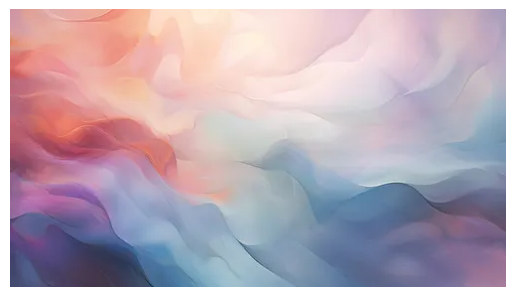

In [21]:
new_bg = cv2.cvtColor(cv2.imread('/kaggle/input/datasets/rufaidakassem/background-changer/background.webp'), cv2.COLOR_BGR2RGB)
plt.imshow(new_bg); plt.axis("off"); plt.show()

In [22]:
def guided_filter(guide, src, r=8, eps=1e-3):
    """Edge-aware smoothing of `src` using `guide` (float32, 2-D, range 0..1)."""
    k = (2 * r + 1, 2 * r + 1)
    mean = lambda x: cv2.boxFilter(x, -1, k)
    mean_I, mean_p = mean(guide), mean(src)
    cov_Ip = mean(guide * src) - mean_I * mean_p
    var_I  = mean(guide * guide) - mean_I * mean_I
    a = cov_Ip / (var_I + eps)
    b = mean_p - a * mean_I
    return mean(a) * guide + mean(b)


def replace_background(frame, new_bg, size=384, erode=3, edge=(0.35, 0.65)):
    global alpha
    model.eval()
    h, w = frame.shape[:2]
    bg = cv2.resize(new_bg, (w, h))

    pre = transforms.Compose([
        transforms.Resize((size, size)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
    x = pre(Image.fromarray(frame)).unsqueeze(0).to(device)

    with torch.no_grad():
        out = model(x)
        out = out['out'] if isinstance(out, dict) else out
        mask = torch.sigmoid(out)[0, 0].cpu().numpy()

    alpha = cv2.resize(mask, (w, h), interpolation=cv2.INTER_LINEAR)

    # 1. Shrink the mask slightly to remove the halo
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*erode+1, 2*erode+1))
    alpha = cv2.erode(alpha, k)

    # 2. Sharpen the transition (smoothstep) instead of a wide blur
    lo, hi = edge
    alpha = np.clip((alpha - lo) / (hi - lo), 0, 1)
    alpha = alpha * alpha * (3 - 2 * alpha)

    # 3. Snap the edge to real image edges (hair) with a guided filter
    guide = cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255.0
    alpha = np.clip(guided_filter(guide, alpha.astype(np.float32), r=8, eps=1e-3), 0, 1)

    a = alpha[..., None]
    return (frame * a + bg * (1 - a)).astype(np.uint8)

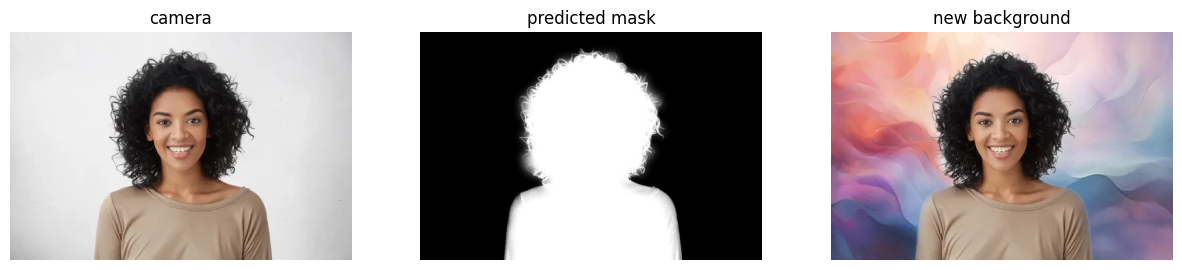

True

In [23]:
# Remove the background and show the result
result = replace_background(frame, new_bg)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(frame);  ax[0].set_title("camera")
ax[1].imshow(alpha, cmap="gray"); ax[1].set_title("predicted mask")
ax[2].imshow(result); ax[2].set_title("new background")
for a in ax: a.axis("off")
plt.show()
cv2.imwrite("result.jpg", cv2.cvtColor(result, cv2.COLOR_RGB2BGR))